# 作业4

使用R语言cluster包中的ruspini数据集，执行一个k均值分析。记录结果并解释所选择的k值。

提示：使用data(ruspini)将数据集加载到R工作区

## 准备工作

### 加载库

In [10]:
library(plyr)
library(ggplot2)
library(cluster)
library(lattice)
library(graphics)
library(grid)
library(gridExtra)

### 加载数据

使用绘图工具和head函数大致了解数据分布情况

,x,y
,<int>,<int>
1,4,53
2,5,63
3,10,59
4,9,77
5,13,49
6,13,69


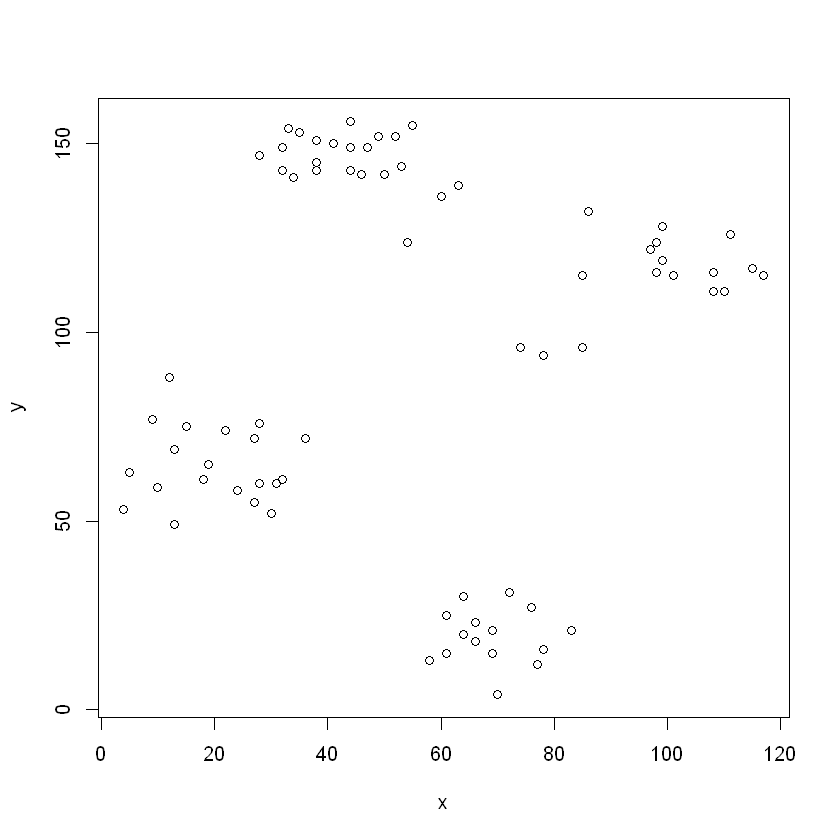

In [11]:
data(ruspini)
Data <- ruspini
head(Data)
plot(Data)

这里可以大致进行预测，数据可以聚类为4类或5类可能会比较合适。也就是k的值取4或5。

生成15个数值型空矢量，用于存放簇内误差平方和

In [12]:
wss <- numeric(15)

## 数据分析

### K值探索

分别使用1-15的k值进行探索分析。对于每个k，选项nstart=25用于指定重复执行25次k均值聚类算法，每次以k个随机初始质心开始。

每次k均值分析得到簇内误差平方和的值，分别存入数组WSS中

In [13]:
for (k in 1:15) {
    wss[k] <- sum(kmeans(Data, centers = k, nstart = 25)$withinss)
}

以x为k的值，y为WSS的值，绘图

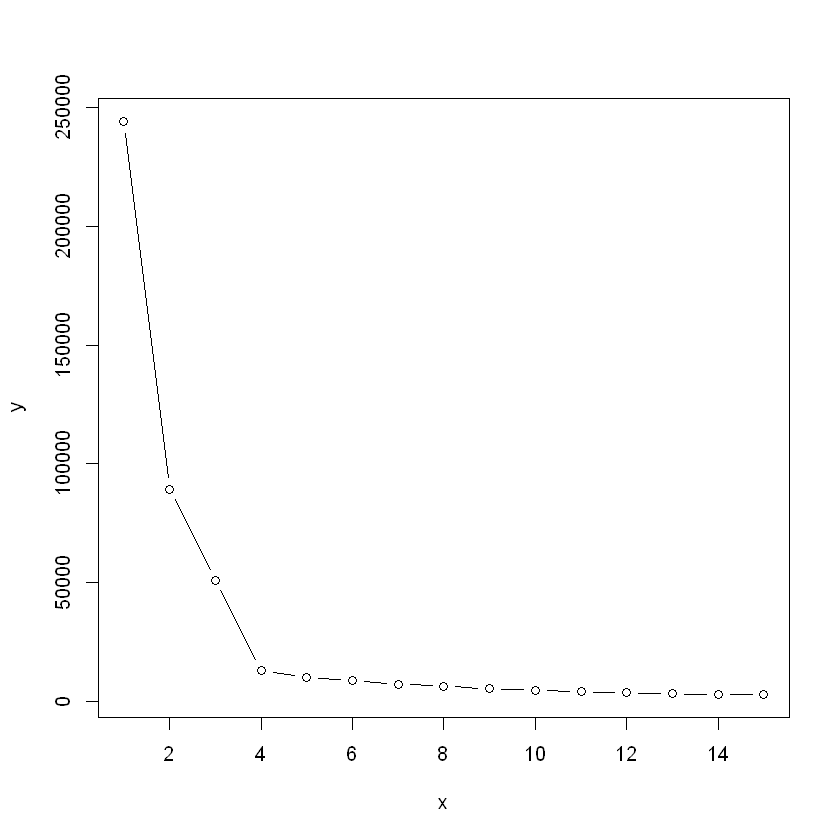

In [14]:
plot(1:15, wss, type = "b", xlab = "x", ylab = "y")

**由上图可知，k取4时，k+1聚类的WSS没有明显小于k聚类。因此，k=4，符合预期**

### 聚类分析

将数据进行4均值聚类运算

In [15]:
km <- kmeans(Data, 4, nstart = 25)
km

K-means clustering with 4 clusters of sizes 15, 17, 23, 20

Cluster means:
         x        y
1 68.93333  19.4000
2 98.17647 114.8824
3 43.91304 146.0435
4 20.15000  64.9500

Clustering vector:
 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 
 4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  3  3  3  3  3  3 
27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 
 3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  2  2  2  2  2  2  2  2  2 
53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 
 2  2  2  2  2  2  2  2  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 

Within cluster sum of squares by cluster:
[1] 1456.533 4558.235 3176.783 3689.500
 (between_SS / total_SS =  94.7 %)

Available components:

[1] "cluster"      "centers"      "totss"        "withinss"     "tot.withinss"
[6] "betweenss"    "size"         "iter"         "ifault"      

### 结果绘制

将km数据集内的centers数据转化为dataframe带入函数kmdf

In [16]:
kmdf <- data.frame(km$centers)
kmdf

,x,y
,<dbl>,<dbl>
1,68.93333,19.4000
2,98.17647,114.8824
3,43.91304,146.0435
4,20.15000,64.9500


根据kmdf绘制每一类质心点位置

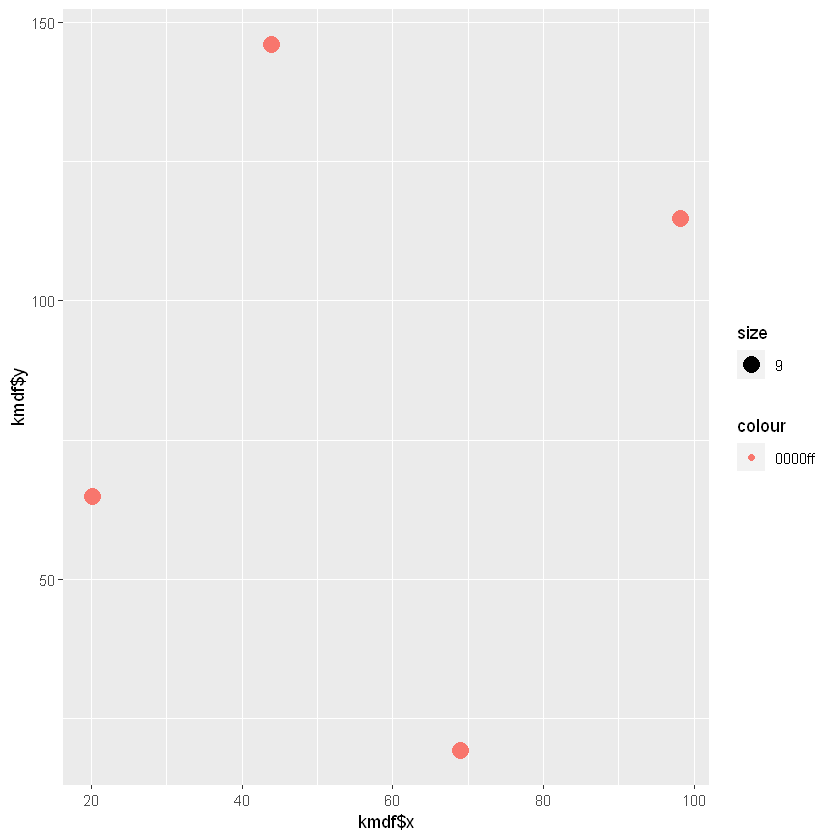

In [17]:
p <- ggplot(data = NULL, mapping = aes(x = kmdf$x, y = kmdf$y))
p <- p + geom_point(aes(size = 9, color = "0000ff"))
p

在此基础上绘制Data数据

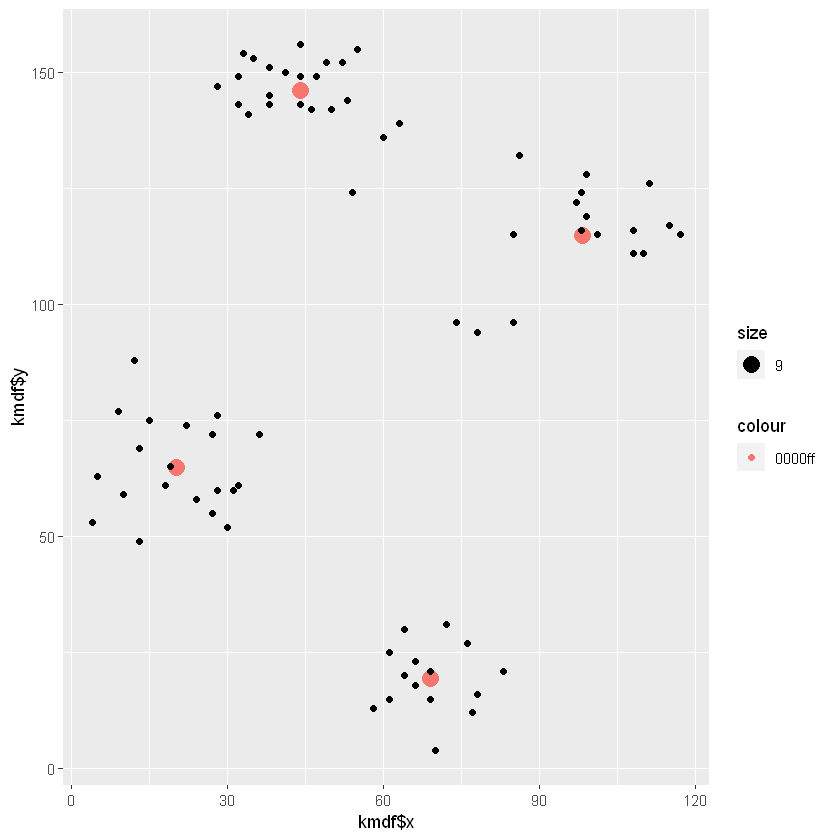

In [18]:
p <- p + geom_point(aes(x = Data$x, y = Data$y))
p